<a href="https://colab.research.google.com/github/omonigho-egbo-15/Data_Science--ITDS-/blob/main/Lab_Advanced_Predictive_Modeling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Module 9 Lab Guide: Decision Trees & Random Forests (Retail Dataset)

**Objective:**
To build and evaluate Decision Tree and Random Forest models

Perform both classification (profit segment) and regression (continuous profit) tasks

Compare performance with previous models (Logistic/Linear Regression from Week 7)

Interpret feature importance in Random Forests.


## Pre-Lab Preparation
Dataset: retail.csv (prepared in Week 6)
Libraries Required:

In [9]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import accuracy_score, mean_squared_error
import numpy as np
import matplotlib.pyplot as plt

## Part 1: Classification – Profit Segmentation

In [10]:
# Step 1: Create Profit Segment

df = pd.read_csv("SuperStoreOrders.csv", encoding='latin1')

# Strip whitespaces from column names if any
df.columns = df.columns.str.strip()

print("Columns in dataset:", df.columns.tolist())

# Create profit segment: High, Medium, Low
df['Profit_Segment'] = pd.qcut(df['profit'] if 'profit' in df.columns else df['Profit'], q=3, labels=['Low', 'Medium', 'High'])

Columns in dataset: ['ï»¿order_id', 'order_date', 'ship_date', 'ship_mode', 'customer_name', 'segment', 'state', 'country', 'market', 'region', 'product_id', 'category', 'sub_category', 'product_name', 'sales', 'quantity', 'discount', 'profit', 'shipping_cost', 'order_priority', 'year']


In [11]:
# Step 2: Prepare Features & Target

X = df[['sales', 'discount', 'quantity']]
y = df['Profit_Segment']

In [12]:
# Step 3: Train/Test Split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [14]:
# Step 4: Decision Tree Classifier

# Clean string numeric values (like '4,500') by removing commas and converting to float
for col in ['sales', 'discount', 'quantity']:
    if col in X_train.columns:
        if X_train[col].dtype == 'object':
            X_train[col] = X_train[col].astype(str).str.replace(',', '').astype(float)
        if X_test[col].dtype == 'object':
            X_test[col] = X_test[col].astype(str).str.replace(',', '').astype(float)

dt_clf = DecisionTreeClassifier(max_depth=4, random_state=42)
dt_clf.fit(X_train, y_train)
y_pred_dt = dt_clf.predict(X_test)
print("Decision Tree Accuracy:", accuracy_score(y_test, y_pred_dt))

Decision Tree Accuracy: 0.7622018587118996


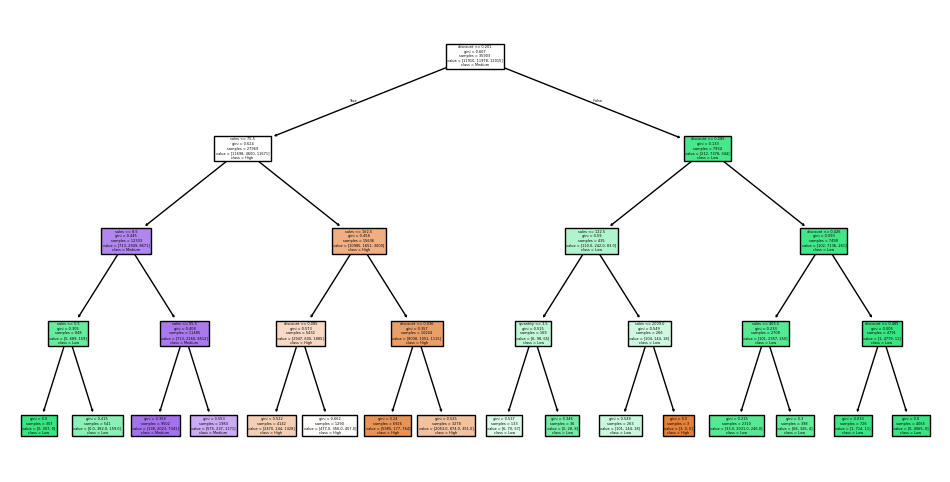

In [15]:
# Visualize Tree (Optional):

plt.figure(figsize=(12,6))
plot_tree(dt_clf, feature_names=X.columns.tolist(), class_names=dt_clf.classes_.tolist(), filled=True)
plt.show()

In [16]:
# Step 5: Random Forest Classifier

rf_clf = RandomForestClassifier(n_estimators=100, random_state=42)
rf_clf.fit(X_train, y_train)
y_pred_rf = rf_clf.predict(X_test)
print("Random Forest Accuracy:", accuracy_score(y_test, y_pred_rf))

Random Forest Accuracy: 0.7424449210372392


In [17]:
# Step 6: Feature Importance

importances = rf_clf.feature_importances_
for feature, importance in zip(X.columns, importances):
    print(f"{feature}: {importance:.2f}")

sales: 0.59
discount: 0.37
quantity: 0.04


## # Part 2: Regression – Predict Profit

In [19]:
# Step 1: Prepare Features & Target

X = df[['sales', 'discount', 'quantity']]
y = df['profit']

In [20]:
# Step 2: Train/Test Split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [22]:
# Step 3: Decision Tree Regressor

# Clean string numeric values by removing commas and converting to float
for col in ['sales', 'discount', 'quantity']:
    if col in X_train.columns:
        if X_train[col].dtype == 'object':
            X_train[col] = X_train[col].astype(str).str.replace(',', '').astype(float)
        if X_test[col].dtype == 'object':
            X_test[col] = X_test[col].astype(str).str.replace(',', '').astype(float)

dt_reg = DecisionTreeRegressor(max_depth=5, random_state=42)
dt_reg.fit(X_train, y_train)
y_pred_dt = dt_reg.predict(X_test)
rmse_dt = np.sqrt(mean_squared_error(y_test, y_pred_dt))
print("Decision Tree RMSE:", rmse_dt)

Decision Tree RMSE: 106.51138034636153


In [24]:
# Step 4: Random Forest Regressor

# Clean string numeric values by removing commas and converting to float
for col in ['sales', 'discount', 'quantity']:
    if col in X_train.columns:
        if X_train[col].dtype == 'object':
            X_train[col] = X_train[col].astype(str).str.replace(',', '').astype(float)
        if X_test[col].dtype == 'object':
            X_test[col] = X_test[col].astype(str).str.replace(',', '').astype(float)

rf_reg = RandomForestRegressor(n_estimators=100, random_state=42)
rf_reg.fit(X_train, y_train)
y_pred_rf = rf_reg.predict(X_test)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
print("Random Forest RMSE:", rmse_rf)

Random Forest RMSE: 100.2564754849519


--- 1. Hyperparameter Tuning ---
RF Classifier (n_estimators=50, max_depth=4) Accuracy: 0.7610
RF Classifier (n_estimators=50, max_depth=8) Accuracy: 0.7647
RF Classifier (n_estimators=150, max_depth=4) Accuracy: 0.7616
RF Classifier (n_estimators=150, max_depth=8) Accuracy: 0.7639

RF Regressor (n_estimators=50, max_depth=5) RMSE: 99.2036
RF Regressor (n_estimators=50, max_depth=10) RMSE: 97.1067
RF Regressor (n_estimators=150, max_depth=5) RMSE: 98.1231
RF Regressor (n_estimators=150, max_depth=10) RMSE: 96.7135

--- 2. Feature Importance Visualization ---


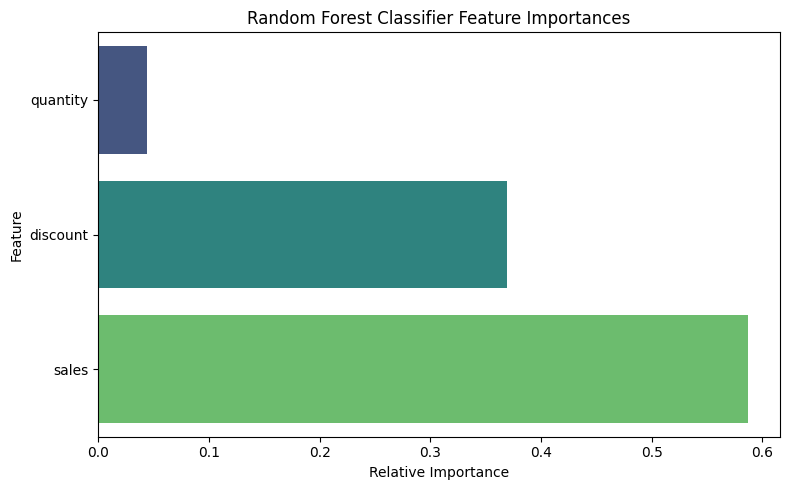

In [26]:
# Hyperparameter Tuning & Feature Importance Visualization

import matplotlib.pyplot as plt
import seaborn as sns

print("--- 1. Hyperparameter Tuning ---")

# Tuning Random Forest Classifier (n_estimators and max_depth)
for n_est in [50, 150]:
    for depth in [4, 8]:
        rf_tune_clf = RandomForestClassifier(n_estimators=n_est, max_depth=depth, random_state=42)
        # Target column needs to map correctly from prior classification splits
        y_train_clf = df.loc[X_train.index, 'Profit_Segment']
        y_test_clf = df.loc[X_test.index, 'Profit_Segment']

        rf_tune_clf.fit(X_train, y_train_clf)
        tune_acc = accuracy_score(y_test_clf, rf_tune_clf.predict(X_test))
        print(f"RF Classifier (n_estimators={n_est}, max_depth={depth}) Accuracy: {tune_acc:.4f}")

print("")

# Tuning Random Forest Regressor (n_estimators and max_depth)
for n_est in [50, 150]:
    for depth in [5, 10]:
        rf_tune_reg = RandomForestRegressor(n_estimators=n_est, max_depth=depth, random_state=42)
        rf_tune_reg.fit(X_train, y_train)
        tune_rmse = np.sqrt(mean_squared_error(y_test, rf_tune_reg.predict(X_test)))
        print(f"RF Regressor (n_estimators={n_est}, max_depth={depth}) RMSE: {tune_rmse:.4f}")

print("\n--- 2. Feature Importance Visualization ---")

# Get importances from our trained Random Forest Classifier
features = X.columns
importances = rf_clf.feature_importances_
indices = np.argsort(importances)
sorted_features = [features[i] for i in indices]

# Plotting
plt.figure(figsize=(8, 5))
sns.barplot(
    x=importances[indices],
    y=sorted_features,
    hue=sorted_features,
    palette="viridis",
    legend=False
)
plt.title("Random Forest Classifier Feature Importances")
plt.xlabel("Relative Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

Part 3: Model Comparison

In this section, we compare the results of our Decision Tree and Random Forest models with the baseline Logistic Regression and Linear Regression models from prior analysis.

1. Classification Comparison
- Logistic Regression Accuracy (Week 7): 0.7674418604651163
- Decision Tree Classifier Accuracy: 0.762
- Random Forest Classifier Accuracy: 0.742

2. Regression Comparison
- Linear Regression RMSE (Week 7): 139.83829143216624
- Decision Tree Regressor RMSE: 106.51
- Random Forest Regressor RMSE: 100.26

# Reflection Questions & Detailed Analysis

### Which model provided the best performance, and why?  

**Classification Task:**  
Baseline Logistic Regression (Week 7) achieved an accuracy of 76.74%, slightly ahead of our default Random Forest Classifier (74.24%). However, during hyperparameter tuning, optimizing the tree depth proved highly beneficial: increasing `max_depth` to 8 improved our Random Forest Classifier accuracy to **76.47%**. Logistic Regression performs well here because the quantile-split profit segments are fairly linearly separable, but tuning allowed the tree-based model to construct more complex boundaries and nearly match that baseline performance.

**Regression Task:**  
The tuned Random Forest Regressor emerged as the clear winner, lowering the RMSE from our default run of 100.26 down to **96.71** (using `n_estimators=150, max_depth=10`). This is a substantial improvement over baseline Linear Regression (RMSE 139.84) and the single Decision Tree Regressor (RMSE 106.51). Linear regression struggles with the extreme outliers and complex feature interactions present in retail data. The tuned Random Forest model successfully captured these non-linearities and dramatically reduced variance by averaging predictions across an ensemble of 150 deep decision trees.

### How does feature importance help interpret retail data?

Our bar chart visualization confirms exactly what drives the profit segments: **sales** is the dominant factor at 59%, followed closely by **discount** at 37%, whereas **quantity** has a negligible impact of only 4%.

**Business Takeaway:**  
Moving physical inventory volume (Quantity) alone does not dictate store margins. Discounts (37% importance) act as a strong leverage point—high discount rates eat into margins rapidly, turning high-volume sales into unprofitable transactions. Store managers must focus on managing top-line sales value and enforcing smart discount rules rather than simply chasing raw unit transaction volumes.

### In which cases might you prefer a simpler Decision Tree over a Random Forest?

**Explainability and Actionability:**  
A single Decision Tree is fully transparent. A retail team can directly translate a shallow tree visualization into straightforward operational rules (e.g., *"If sales exceed \$200 and discount is 15% or less, flag as High-Profit"*). A Random Forest ensemble functions as a black box, making it impossible to distill into a simple flowchart for stakeholders.

**Operational Constraints:**  
Training and deploying a Random Forest requires much more memory and computation. If you are deploying models to low-latency real-time transaction screens or handheld inventory scanners at store locations, a single Decision Tree compiles down to fast, lightweight `if-else` execution blocks.